In [1]:
# 1. Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# 2. Locate SMS Dataset

raw_dir = Path("../datasets/raw")

print("Dataset folder:", raw_dir.resolve())

if raw_dir.exists():
    print("\nAvailable files:")
    for file in raw_dir.iterdir():
        print(file.name)
else:
    print("Dataset folder not found!")

Dataset folder: C:\Users\x1605\AI_Projects\ScamShield\Training\datasets\raw

Available files:
PhiUSIIL_Phishing_URL_Dataset.csv
SMSSpamCollection


In [3]:
# 3. Load SMS Dataset

sms_files = [
    file for file in raw_dir.iterdir()
    if "smsspamcollection" in file.name.lower()
]

if not sms_files:
    print("SMS dataset not found. Check datasets/raw folder.")
else:
    sms_path = sms_files[0]

    df = pd.read_csv(
        sms_path,
        sep="\t",
        header=None,
        names=["label", "message"],
        encoding="utf-8"
    )

    print("Dataset loaded successfully!")
    print("Dataset shape:", df.shape)

    display(df.head(10))

Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


In [4]:
# Basic Dataset Information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nFirst 5 Records:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())


Dataset Shape: (5572, 2)

Column Names:
['label', 'message']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5572 non-null   str  
 1   message  5572 non-null   str  
dtypes: str(2)
memory usage: 87.2 KB

First 5 Records:


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."



Missing Values:
label      0
message    0
dtype: int64

Duplicate Records: 403


In [5]:
# Count SMS Categories

label_counts = df["label"].value_counts()

print(label_counts)

print("\nPercentage Distribution:")
print(df["label"].value_counts(normalize=True) * 100)

label
ham     4825
spam     747
Name: count, dtype: int64

Percentage Distribution:
label
ham     86.593683
spam    13.406317
Name: proportion, dtype: float64


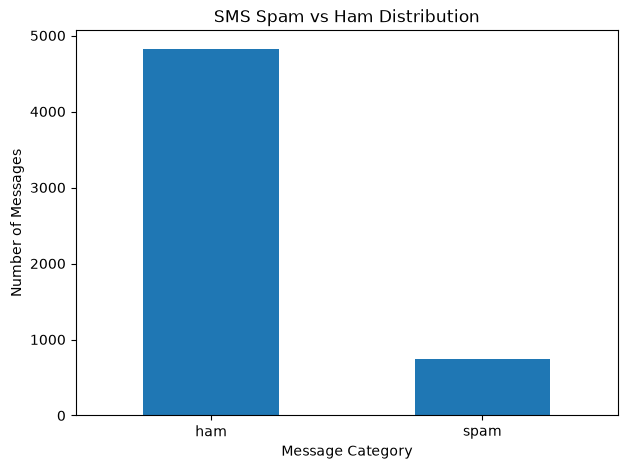

In [6]:
# Visualize Class Distribution

plt.figure(figsize=(7, 5))

label_counts.plot(kind="bar")

plt.title("SMS Spam vs Ham Distribution")
plt.xlabel("Message Category")
plt.ylabel("Number of Messages")
plt.xticks(rotation=0)

plt.show()

In [7]:
# Calculate Message Length

df["message_length"] = df["message"].astype(str).apply(len)

display(df[["label", "message", "message_length"]].head())

print("\nAverage Message Length:")
print(df.groupby("label")["message_length"].mean())

,label,message,message_length
0,ham,"Go until jurong point, crazy.. Available only ...",111
1,ham,Ok lar... Joking wif u oni...,29
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,ham,U dun say so early hor... U c already then say...,49
4,ham,"Nah I don't think he goes to usf, he lives aro...",61



Average Message Length:
label
ham      71.482487
spam    138.670683
Name: message_length, dtype: float64


In [8]:
# Check duplicate messages with conflicting labels

duplicate_rows = df[df.duplicated(
    subset=["label", "message"],
    keep=False
)]

print("Total duplicate rows:", len(duplicate_rows))

# Check whether the same message has different labels

label_conflicts = (
    df.groupby("message")["label"]
    .nunique()
)

conflicting_messages = label_conflicts[
    label_conflicts > 1
]

print("Messages with conflicting labels:",
      len(conflicting_messages))

# Display conflicting messages, if any

if len(conflicting_messages) > 0:
    display(
        df[df["message"].isin(conflicting_messages.index)]
    )
else:
    print("No conflicting labels found!")
    

Total duplicate rows: 684
Messages with conflicting labels: 0
No conflicting labels found!


In [9]:
# Step 1: Create a clean copy

df_clean = df.copy()

# Normalize labels and messages
df_clean["label"] = df_clean["label"].str.strip().str.lower()
df_clean["message"] = df_clean["message"].str.strip()

# Remove exact duplicate records
initial_rows = len(df_clean)

df_clean = df_clean.drop_duplicates(
    subset=["label", "message"],
    keep="first"
).copy()

# Remove empty messages
df_clean = df_clean[df_clean["message"] != ""].copy()

# Display results
print("Original Records:", initial_rows)
print("Cleaned Records:", len(df_clean))
print("Removed Records:", initial_rows - len(df_clean))

print("\nRemaining Duplicates:",
      df_clean.duplicated(subset=["label", "message"]).sum())

print("\nClass Distribution:")
print(df_clean["label"].value_counts())

Original Records: 5572
Cleaned Records: 5158
Removed Records: 414

Remaining Duplicates: 0

Class Distribution:
label
ham     4516
spam     642
Name: count, dtype: int64


In [10]:
# Step 2: Encode Labels

label_mapping = {
    "ham": 0,
    "spam": 1
}

df_clean["target"] = df_clean["label"].map(label_mapping)

print(df_clean[["label", "target"]].head(10))

print("\nEncoded Labels:")
print(df_clean["target"].value_counts())

  label  target
0   ham       0
1   ham       0
2  spam       1
3   ham       0
4   ham       0
5  spam       1
6   ham       0
7   ham       0
8  spam       1
9  spam       1

Encoded Labels:
target
0    4516
1     642
Name: count, dtype: int64


In [11]:
# Check conflicting labels after cleaning

conflicts = df_clean.groupby("message")["label"].nunique()

conflicts = conflicts[conflicts > 1]

print("Conflicting messages:", len(conflicts))

if len(conflicts) > 0:
    display(df_clean[df_clean["message"].isin(conflicts.index)])
else:
    print("No conflicting labels. Dataset is ready!")

Conflicting messages: 0
No conflicting labels. Dataset is ready!


In [12]:
from sklearn.model_selection import train_test_split

# Input and target
X = df_clean["message"]
y = df_clean["target"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

print("\nTraining Distribution:")
print(y_train.value_counts())

print("\nTesting Distribution:")
print(y_test.value_counts())

Training Records: 4126
Testing Records: 1032

Training Distribution:
target
0    3612
1     514
Name: count, dtype: int64

Testing Distribution:
target
0    904
1    128
Name: count, dtype: int64


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

print("TF-IDF imported successfully!")

TF-IDF imported successfully!


In [14]:
tfidf = TfidfVectorizer(
    max_features=2000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

print("TF-IDF Vectorizer initialized!")

TF-IDF Vectorizer initialized!


In [15]:
# Fit only on training messages
X_train_tfidf = tfidf.fit_transform(X_train)

# Transform testing messages
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("\nVocabulary Size:", len(tfidf.vocabulary_))

Training TF-IDF Shape: (4126, 2000)
Testing TF-IDF Shape: (1032, 2000)

Vocabulary Size: 2000


In [16]:
feature_names = tfidf.get_feature_names_out()

print("First 30 TF-IDF Features:")
print(feature_names[:30])

First 30 TF-IDF Features:
['00' '000' '000 cash' '02' '03' '03 this' '04' '0800' '08000839402'
 '08000839402 or' '08000930705' '10' '100' '1000' '1000 cash' '10p' '11'
 '12' '12hrs' '12hrs only' '150' '150p' '150p msg' '150ppm' '16' '18'
 '1st' '1st week' '20' '200']


In [17]:
print("Training TF-IDF Shape:", X_train_tfidf.shape)
print("Testing TF-IDF Shape:", X_test_tfidf.shape)

print("Vocabulary Size:", len(tfidf.vocabulary_))

Training TF-IDF Shape: (4126, 2000)
Testing TF-IDF Shape: (1032, 2000)
Vocabulary Size: 2000


In [18]:
import re

# Define SMS feature columns
SMS_FEATURE_COLUMNS = [
    "char_count",
    "word_count",
    "url_count",
    "has_url",
    "uppercase_ratio",
    "digit_ratio",
    "special_char_count",
    "keyword_hits",
    "exclamation_count",
    "question_count"
]

# Suspicious keyword vocabulary
SCAM_KEYWORDS = [
    "urgent", "winner", "won", "free", "claim",
    "prize", "cash", "guaranteed", "offer",
    "credit", "loan", "verify", "login",
    "click", "award", "congratulations",
    "selected", "limited", "immediately",
    "suspended", "blocked", "password",
    "otp", "bank", "kyc", "payment"
]

# Detect URLs with or without HTTP/HTTPS
URL_PATTERN = re.compile(
    r"(?i)(?<![@\w])(?:https?://|www\.)?"
    r"[a-z0-9-]+(?:\.[a-z0-9-]+)+"
    r"(?:/[^\s<>\"']*)?"
)


def extract_sms_features(message):

    message = str(message)
    lower_message = message.lower()

    total_chars = len(message)

    # Character and word features
    char_count = total_chars
    word_count = len(message.split())

    # URL features
    urls = URL_PATTERN.findall(message)
    url_count = len(urls)
    has_url = int(url_count > 0)

    # Uppercase ratio
    uppercase_ratio = (
        sum(char.isupper() for char in message) / total_chars
        if total_chars > 0 else 0
    )

    # Digit ratio
    digit_ratio = (
        sum(char.isdigit() for char in message) / total_chars
        if total_chars > 0 else 0
    )

    # Special characters
    special_char_count = len(
        re.findall(r"[!?$#@*]", message)
    )

    # Suspicious keyword hits
    keyword_hits = sum(
        len(re.findall(
            r"(?<!\w)" + re.escape(word) + r"(?!\w)",
            lower_message
        ))
        for word in SCAM_KEYWORDS
    )

    # Punctuation features
    exclamation_count = message.count("!")
    question_count = message.count("?")

    return {
        "char_count": char_count,
        "word_count": word_count,
        "url_count": url_count,
        "has_url": has_url,
        "uppercase_ratio": uppercase_ratio,
        "digit_ratio": digit_ratio,
        "special_char_count": special_char_count,
        "keyword_hits": keyword_hits,
        "exclamation_count": exclamation_count,
        "question_count": question_count
    }


print("SMS Feature Extraction Function Created!")

SMS Feature Extraction Function Created!


In [19]:
# Extract numerical features

X_train_num = pd.DataFrame(
    [extract_sms_features(msg) for msg in X_train],
    index=X_train.index,
    columns=SMS_FEATURE_COLUMNS
)

X_test_num = pd.DataFrame(
    [extract_sms_features(msg) for msg in X_test],
    index=X_test.index,
    columns=SMS_FEATURE_COLUMNS
)

print("Training Numerical Features:", X_train_num.shape)
print("Testing Numerical Features:", X_test_num.shape)

display(X_train_num.head())

Training Numerical Features: (4126, 10)
Testing Numerical Features: (1032, 10)


,char_count,word_count,url_count,has_url,uppercase_ratio,digit_ratio,special_char_count,keyword_hits,exclamation_count,question_count
3351,368,70,1,1,0.019022,0.002717,0,0,0,0
1637,165,36,0,0,0.030303,0.000000,0,0,0,0
2228,32,6,1,1,0.031250,0.000000,1,0,0,1
2581,133,25,0,0,0.082707,0.127820,0,0,0,0
1176,150,33,0,0,0.026667,0.013333,1,0,0,1


In [20]:
print("Training Missing Values:")
print(X_train_num.isnull().sum())

print("\nTesting Missing Values:")
print(X_test_num.isnull().sum())

Training Missing Values:
char_count            0
word_count            0
url_count             0
has_url               0
uppercase_ratio       0
digit_ratio           0
special_char_count    0
keyword_hits          0
exclamation_count     0
question_count        0
dtype: int64

Testing Missing Values:
char_count            0
word_count            0
url_count             0
has_url               0
uppercase_ratio       0
digit_ratio           0
special_char_count    0
keyword_hits          0
exclamation_count     0
question_count        0
dtype: int64


In [21]:
from scipy.sparse import hstack, csr_matrix

# Convert numerical features into sparse matrices
X_train_num_sparse = csr_matrix(
    X_train_num.to_numpy(dtype=np.float32)
)

X_test_num_sparse = csr_matrix(
    X_test_num.to_numpy(dtype=np.float32)
)

# Combine TF-IDF and numerical features
X_train_combined = hstack(
    [X_train_tfidf, X_train_num_sparse],
    format="csr"
)

X_test_combined = hstack(
    [X_test_tfidf, X_test_num_sparse],
    format="csr"
)

print("Training Shape:", X_train_combined.shape)
print("Testing Shape:", X_test_combined.shape)

print("\nTotal Features:", X_train_combined.shape[1])

Training Shape: (4126, 2010)
Testing Shape: (1032, 2010)

Total Features: 2010


In [22]:
from sklearn.ensemble import RandomForestClassifier

# Initialize Random Forest Classifier
sms_model = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model
print("Training SMS Random Forest Model...")

sms_model.fit(X_train_combined, y_train)

print("\nModel Training Completed Successfully!")

print("Number of Trees:", sms_model.n_estimators)
print("Model Classes:", sms_model.classes_)
print("Training Samples:", X_train_combined.shape[0])
print("Total Features:", X_train_combined.shape[1])

Training SMS Random Forest Model...

Model Training Completed Successfully!
Number of Trees: 200
Model Classes: [0 1]
Training Samples: 4126
Total Features: 2010


In [23]:
# Generate predictions on test data

y_pred = sms_model.predict(X_test_combined)

# Generate prediction probabilities
y_prob = sms_model.predict_proba(X_test_combined)

print("Predictions generated successfully!")
print("Total Predictions:", len(y_pred))

print("\nFirst 10 Predictions:")
print(y_pred[:10])

Predictions generated successfully!
Total Predictions: 1032

First 10 Predictions:
[0 0 0 0 0 0 0 0 0 0]


In [24]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label=1)
recall = recall_score(y_test, y_pred, pos_label=1)
f1 = f1_score(y_test, y_pred, pos_label=1)

print("===== SMS MODEL EVALUATION =====")

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"],
    zero_division=0
))

===== SMS MODEL EVALUATION =====
Accuracy  : 0.9903
Precision : 0.9917
Recall    : 0.9297
F1-Score  : 0.9597

Classification Report:
              precision    recall  f1-score   support

         Ham       0.99      1.00      0.99       904
        Spam       0.99      0.93      0.96       128

    accuracy                           0.99      1032
   macro avg       0.99      0.96      0.98      1032
weighted avg       0.99      0.99      0.99      1032



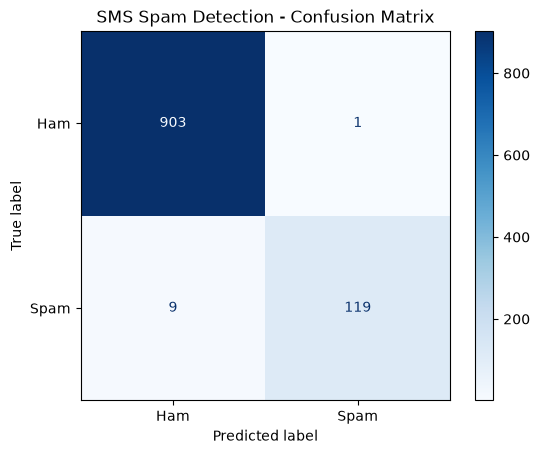

In [25]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues")
plt.title("SMS Spam Detection - Confusion Matrix")
plt.show()

In [26]:
import joblib
import json
from pathlib import Path

# Create model and report directories
model_dir = Path("../Models")
report_dir = Path("../Reports")

model_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

# Save trained Random Forest model
joblib.dump(
    sms_model,
    model_dir / "sms_rf_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    model_dir / "sms_tfidf_vectorizer.pkl"
)

# Save feature extraction metadata
metadata = {
    "feature_columns": SMS_FEATURE_COLUMNS,
    "scam_keywords": SCAM_KEYWORDS,
    "url_pattern": URL_PATTERN.pattern,
    "label_mapping": {
        "ham": 0,
        "spam": 1
    },
    "feature_order": [
        "TF-IDF features (2000)",
        "Numerical features (10)"
    ]
}

joblib.dump(
    metadata,
    model_dir / "sms_feature_metadata.pkl"
)

print("SMS model and supporting files saved successfully!")

SMS model and supporting files saved successfully!


In [27]:
# Load saved model
loaded_sms_model = joblib.load(
    "../Models/sms_rf_model.pkl"
)

loaded_tfidf = joblib.load(
    "../Models/sms_tfidf_vectorizer.pkl"
)

# Verify model dimensions
print("Model Loaded Successfully!")
print("Number of Trees:", loaded_sms_model.n_estimators)
print("Expected Features:", loaded_sms_model.n_features_in_)
print("TF-IDF Vocabulary:", len(loaded_tfidf.vocabulary_))

# Verify predictions are unchanged
original_predictions = sms_model.predict(X_test_combined[:10])

loaded_predictions = loaded_sms_model.predict(X_test_combined[:10])

print("\nPredictions Match:",
      np.array_equal(original_predictions, loaded_predictions))

Model Loaded Successfully!
Number of Trees: 200
Expected Features: 2010
TF-IDF Vocabulary: 2000

Predictions Match: True


In [28]:
import joblib
import json
from pathlib import Path

# Create directories
model_dir = Path("../Models")
report_dir = Path("../Reports")

model_dir.mkdir(parents=True, exist_ok=True)
report_dir.mkdir(parents=True, exist_ok=True)

# Save Random Forest model
joblib.dump(
    sms_model,
    model_dir / "sms_rf_model.pkl"
)

# Save TF-IDF vectorizer
joblib.dump(
    tfidf,
    model_dir / "sms_tfidf_vectorizer.pkl"
)

# Save feature metadata
metadata = {
    "feature_columns": SMS_FEATURE_COLUMNS,
    "scam_keywords": SCAM_KEYWORDS,
    "url_pattern": URL_PATTERN.pattern,
    "label_mapping": {
        "ham": 0,
        "spam": 1
    },
    "tfidf_features": 2000,
    "numerical_features": 10,
    "total_features": 2010,
    "n_estimators": 200
}

joblib.dump(
    metadata,
    model_dir / "sms_feature_metadata.pkl"
)

# Save evaluation report
evaluation = {
    "accuracy": float(accuracy),
    "precision": float(precision),
    "recall": float(recall),
    "f1_score": float(f1),
    "confusion_matrix": cm.tolist(),
    "test_samples": len(y_test)
}

with open(report_dir / "sms_evaluation.json", "w") as file:
    json.dump(evaluation, file, indent=4)

print("SMS Model Saved Successfully!")
print("\nSaved Files:")

for file in model_dir.iterdir():
    print(file.name)

print("\nEvaluation report saved successfully!")

SMS Model Saved Successfully!

Saved Files:
sms_feature_metadata.pkl
sms_rf_model.pkl
sms_tfidf_vectorizer.pkl
url_feature_metadata.json
url_rf_model.pkl

Evaluation report saved successfully!


In [29]:
# Load saved components

loaded_model = joblib.load(
    "../Models/sms_rf_model.pkl"
)

loaded_vectorizer = joblib.load(
    "../Models/sms_tfidf_vectorizer.pkl"
)

# Verify model configuration

print("Model Loaded:", loaded_model is not None)
print("Number of Trees:", loaded_model.n_estimators)
print("Model Features:", loaded_model.n_features_in_)
print("Vectorizer Vocabulary:", len(loaded_vectorizer.vocabulary_))

# Compare predictions
original_predictions = sms_model.predict(X_test_combined[:10])

loaded_predictions = loaded_model.predict(X_test_combined[:10])

print("\nPredictions Match:",
      np.array_equal(original_predictions, loaded_predictions))

Model Loaded: True
Number of Trees: 200
Model Features: 2010
Vectorizer Vocabulary: 2000

Predictions Match: True


In [30]:
sample_message = (
    "Congratulations! You have won a free prize. "
    "Click now to claim your reward!"
)

# Extract TF-IDF features
sample_tfidf = loaded_vectorizer.transform([sample_message])

# Extract numerical features
sample_numeric = pd.DataFrame(
    [extract_sms_features(sample_message)],
    columns=SMS_FEATURE_COLUMNS
)

# Combine features
sample_combined = hstack(
    [
        sample_tfidf,
        csr_matrix(sample_numeric.to_numpy(dtype=np.float32))
    ],
    format="csr"
)

# Predict
sample_prediction = loaded_model.predict(sample_combined)[0]
sample_probability = loaded_model.predict_proba(sample_combined)[0]

positive_index = list(loaded_model.classes_).index(1)
spam_probability = sample_probability[positive_index]

print("Message:", sample_message)
print("Prediction:", "SPAM" if sample_prediction == 1 else "HAM")
print(f"Spam Probability: {spam_probability:.2%}")

Message: Congratulations! You have won a free prize. Click now to claim your reward!
Prediction: SPAM
Spam Probability: 74.50%
